# Constraints

Compare degree and total-edge limits, then require a terminal to be a leaf. Each constraint changes the selected tree.

Download {download}`this notebook <constraints.ipynb>` to run it locally.
Install the example dependencies with `pip install steinerpy matplotlib ipykernel`.
All solves below use the default HiGHS backend.

In [1]:
import logging
import matplotlib.pyplot as plt
import networkx as nx
from steinerpy import Problem

# Keep the example output focused on results; solver errors still propagate.
logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("steinerpy").setLevel(logging.WARNING)
plt.rcParams.update({"figure.dpi": 140, "font.size": 11, "figure.facecolor": "white"})

## Degree and total-edge limits

The cheapest tree connects A, B, and D through O. It uses three edges and
gives O degree three. `max_degree=2` prevents that branching. `hop_limit=2`
limits the total number of selected edges, so only a two-edge tree qualifies.
It does not limit each individual root-to-terminal path.

In [2]:
graph = nx.Graph()
graph.add_weighted_edges_from([
    ("A", "O", 1), ("B", "O", 1), ("D", "O", 1),
    ("A", "B", 2), ("B", "D", 3), ("A", "D", 5),
])
positions = {"A": (0, 1), "B": (2, 1), "D": (1, -1), "O": (1, 0.25)}
terminals = ["A", "B", "D"]
plain = Problem(graph, terminals=terminals).get_solution(time_limit=30)
degree = Problem(graph, terminals=terminals, max_degree=2).get_solution(time_limit=30)
hops = Problem(graph, terminals=terminals, hop_limit=2).get_solution(time_limit=30)
for (name, solution, cost) in [('Plain', plain, 3), ('Degree limit', degree, 4), ('Edge limit', hops, 5)]:
    print(f'{name}: cost {solution.objective:g}, {len(solution.edges)} edges')

Plain: cost 3, 3 edges
Degree limit: cost 4, 3 edges
Edge limit: cost 5, 2 edges


In [3]:
for name, solution, cost in [("Plain", plain, 3), ("Degree limit", degree, 4), ("Edge limit", hops, 5)]:
    assert solution.objective == cost and solution.gap == 0
    selected = graph.edge_subgraph(solution.edges)
    assert all(nx.has_path(selected, "A", terminal) for terminal in terminals)
    assert sum(graph[u][v]["weight"] for u, v in solution.edges) == cost
assert max(dict(graph.edge_subgraph(degree.edges).degree()).values()) <= 2
assert len(hops.edges) <= 2

In [4]:
def draw(graph, positions, ax, title, solution=None, terminals=(), groups=(), root=None):
    """Plot original edges and highlight a returned selection at fixed positions."""
    ax.set_facecolor("white")
    arrow_options = {"arrowsize": 18} if graph.is_directed() else {}
    nx.draw_networkx_edges(graph, positions, ax=ax, edge_color="#b8bec5",
                           style="dashed", width=1.3, node_size=620, **arrow_options)
    if solution is not None:
        nx.draw_networkx_edges(graph, positions, ax=ax, edgelist=solution.edges,
                               edge_color="#007a78", width=3, node_size=620,
                               **arrow_options)
    marked = set(terminals) | {node for group in groups for node in group}
    if root is not None:
        marked.add(root)
    ordinary = [node for node in graph if node not in marked]
    nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=ordinary,
                           node_color="#f5f7fa", edgecolors="#374151", node_size=620)
    if terminals:
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=list(terminals),
                               node_shape="s", node_color="#ffdc8b",
                               edgecolors="#374151", node_size=620)
    for idx, group in enumerate(groups):
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=group,
                               node_shape=["s", "^"][idx % 2],
                               node_color=["#c2e4f5", "#ffd3a8"][idx % 2],
                               edgecolors="#374151", node_size=620)
    if root is not None:
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=[root],
                               node_shape="D", node_color="#dbcdf3",
                               edgecolors="#374151", node_size=620)
    nx.draw_networkx_labels(graph, positions, ax=ax, font_size=11,
                            font_color="#17212b")
    nx.draw_networkx_edge_labels(graph, positions, ax=ax,
                                 edge_labels=nx.get_edge_attributes(graph, "weight"),
                                 font_size=10, rotate=False)
    ax.set_title(title, color="#17212b", pad=12)
    ax.margins(0.25)
    ax.set_axis_off()

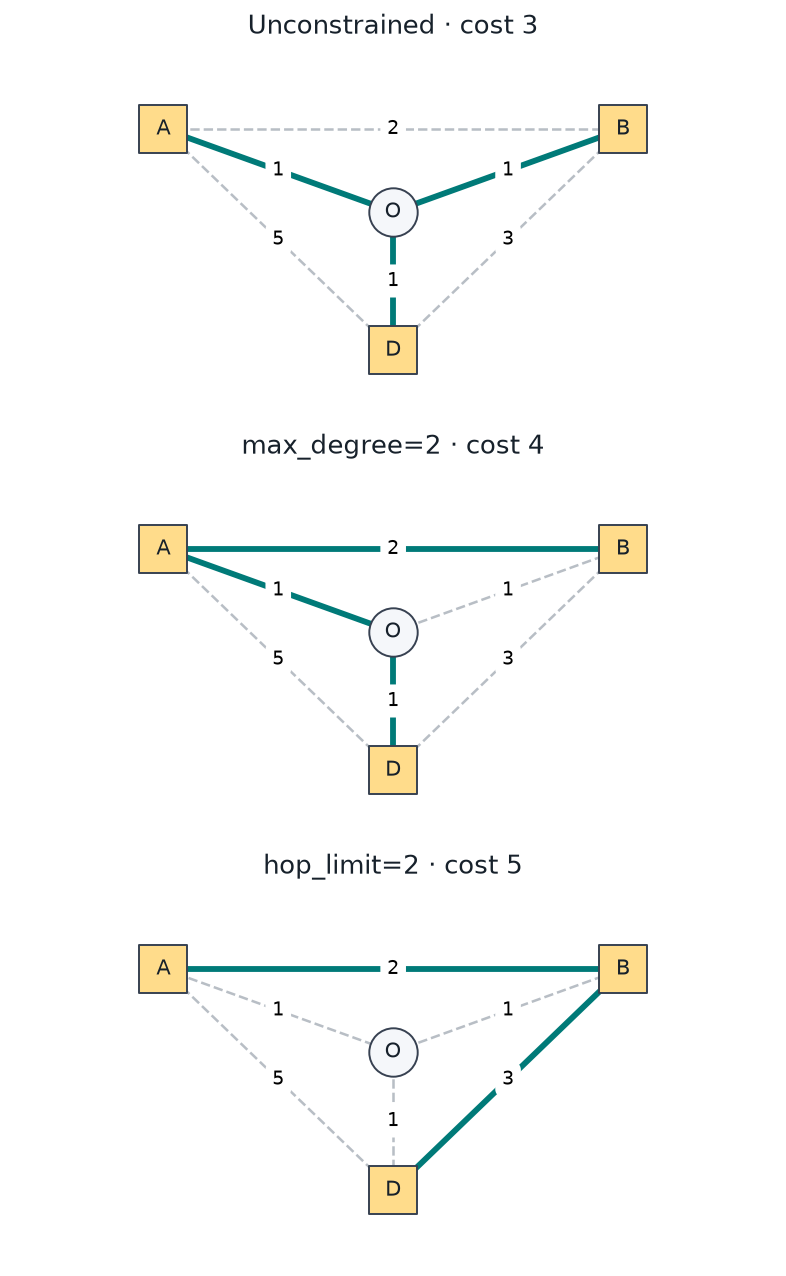

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(5.5, 9), layout="constrained")
for ax, solution, title in zip(axes, [plain, degree, hops], [
    "Unconstrained · cost 3", "max_degree=2 · cost 4", "hop_limit=2 · cost 5",
]):
    draw(graph, positions, ax, title, solution, terminals=terminals)
plt.show()

## Make a terminal a leaf

On this smaller graph, B is normally an internal node on the A–D path.
`partial_terminals=["B"]` requires its degree to be at most one. Since B is
a required terminal, the new solution attaches it as a leaf and uses A–D.

In [6]:
leaf_graph = nx.Graph()
leaf_graph.add_weighted_edges_from([("A", "B", 1), ("B", "D", 2), ("A", "D", 4)])
leaf_positions = {"A": (0, 0), "B": (1, 1), "D": (2, 0)}
ordinary = Problem(leaf_graph, terminals=terminals).get_solution(time_limit=30)
leaf = Problem(leaf_graph, terminals=terminals, partial_terminals=["B"]).get_solution(time_limit=30)
print(f"Without leaf constraint: {ordinary.objective:g}; B as a leaf: {leaf.objective:g}")

Without leaf constraint: 3; B as a leaf: 5


In [7]:
assert ordinary.objective == 3 and leaf.objective == 5
assert ordinary.gap == leaf.gap == 0
selected = leaf_graph.edge_subgraph(leaf.edges)
assert selected.degree("B") == 1
assert nx.is_connected(selected) and set(terminals) <= set(selected)
assert sum(leaf_graph[u][v]["weight"] for u, v in leaf.edges) == leaf.objective

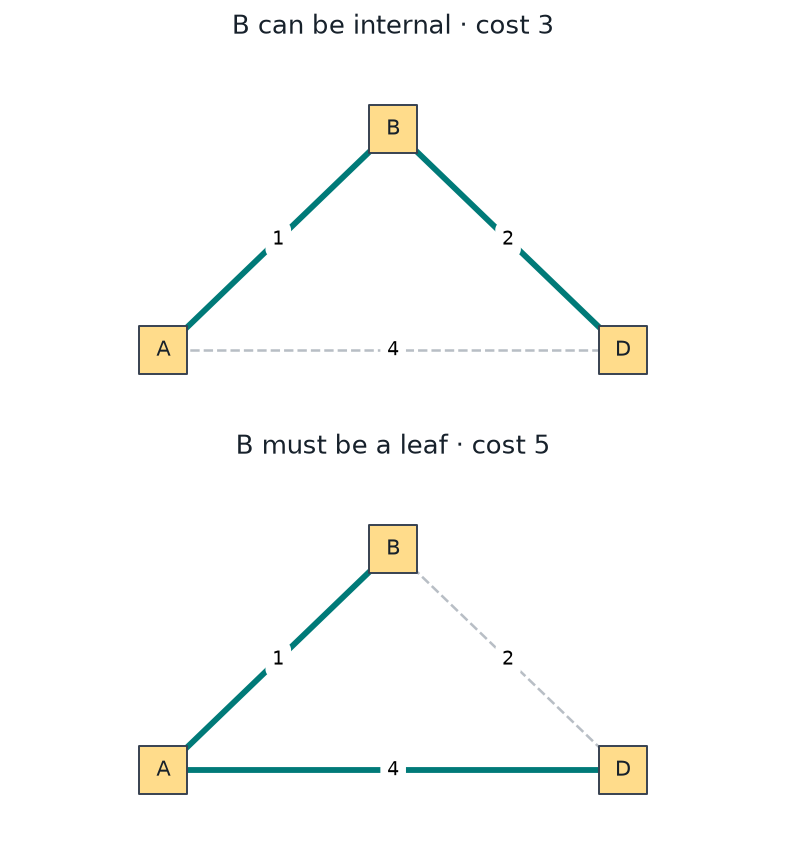

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(5.5, 6), layout="constrained")
draw(leaf_graph, leaf_positions, axes[0], "B can be internal · cost 3", ordinary, terminals)
draw(leaf_graph, leaf_positions, axes[1], "B must be a leaf · cost 5", leaf, terminals)
plt.show()

On directed graphs, `max_degree` counts incoming plus outgoing original
arcs. Constraints can also make a model infeasible; if no feasible incumbent
is available, solving raises `RuntimeError`. See
[solving and interpreting results](../guide/solvers.md) and the
[compatibility reference](../reference/compatibility.md) before combining
constraints with legacy transformed variants.